In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

data = fetch_california_housing(as_frame=True)
df = data.frame.copy()

print("Dataset shape:", df.shape)
display(df.head())

print("\nMissing values:")
print(df.isnull().sum().sum())


Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Missing values:
0


In [3]:

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Number of features:", X_train.shape[1])


Training rows: 16512
Testing rows: 4128
Number of features: 8


In [4]:

baseline_model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

print("BASELINE MODEL")
print("----------------------")
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²:   {baseline_r2:.4f}")


BASELINE MODEL
----------------------
MAE:  0.5332
RMSE: 0.7456
R²:   0.5758


In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

# Create the model pipeline
tuned_pipeline = Pipeline(steps=[
    ("model", HistGradientBoostingRegressor(random_state=42))
])

# Parameters to test
param_distributions = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_iter": [100, 200, 300],
    "model__max_leaf_nodes": [15, 31, 45],
    "model__l2_regularization": [0.0, 0.5, 1.0]
}

# Cross-validation on training data only
cv = KFold(n_splits=3, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=tuned_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation RMSE:")
print(round(np.sqrt(-random_search.best_score_), 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'model__max_leaf_nodes': 31, 'model__max_iter': 300, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}

Best cross-validation RMSE:
0.4704


In [6]:
# Get the best model selected by cross-validation
best_model = random_search.best_estimator_

# Predict on the untouched test set
tuned_pred = best_model.predict(X_test)

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("TUNED MODEL")
print("----------------------")
print(f"MAE:  {tuned_mae:.4f}")
print(f"RMSE: {tuned_rmse:.4f}")
print(f"R²:   {tuned_r2:.4f}")

print("\nBASELINE vs TUNED MODEL")
print("----------------------")
print(f"Baseline MAE:  {baseline_mae:.4f} | Tuned MAE:  {tuned_mae:.4f}")
print(f"Baseline RMSE: {baseline_rmse:.4f} | Tuned RMSE: {tuned_rmse:.4f}")
print(f"Baseline R²:   {baseline_r2:.4f} | Tuned R²:   {tuned_r2:.4f}")

rmse_improvement = (
    (baseline_rmse - tuned_rmse) / baseline_rmse
) * 100

print(f"\nRMSE improvement: {rmse_improvement:.2f}%")

TUNED MODEL
----------------------
MAE:  0.2999
RMSE: 0.4518
R²:   0.8442

BASELINE vs TUNED MODEL
----------------------
Baseline MAE:  0.5332 | Tuned MAE:  0.2999
Baseline RMSE: 0.7456 | Tuned RMSE: 0.4518
Baseline R²:   0.5758 | Tuned R²:   0.8442

RMSE improvement: 39.40%


In [8]:

# Create a table for analyzing prediction errors
error_df = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": tuned_pred
})

error_df["Error"] = error_df["Actual"] - error_df["Predicted"]
error_df["Absolute_Error"] = error_df["Error"].abs()

# Group houses by actual price range
error_df["Price_Range"] = pd.cut(
    error_df["Actual"],
    bins=[0, 1, 2, 3, 4, 5.1],
    labels=["Under $100K", "$100K-$200K", "$200K-$300K",
            "$300K-$400K", "$400K+"],
    include_lowest=True
)

# Summarize errors for each price group
price_error_analysis = error_df.groupby(
    "Price_Range", observed=False
).agg(
    Number_of_Houses=("Actual", "count"),
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean"),
    Average_Error=("Error", "mean")
).round(3)

display(price_error_analysis)


,Number_of_Houses,Mean_Actual,Mean_Predicted,MAE,Average_Error
Price_Range,,,,,
Under $100K,739,0.760,0.935,0.208,-0.175
$100K-$200K,1682,1.517,1.608,0.224,-0.092
$200K-$300K,956,2.447,2.436,0.320,0.011
$300K-$400K,412,3.459,3.310,0.463,0.149
$400K+,339,4.736,4.184,0.619,0.552


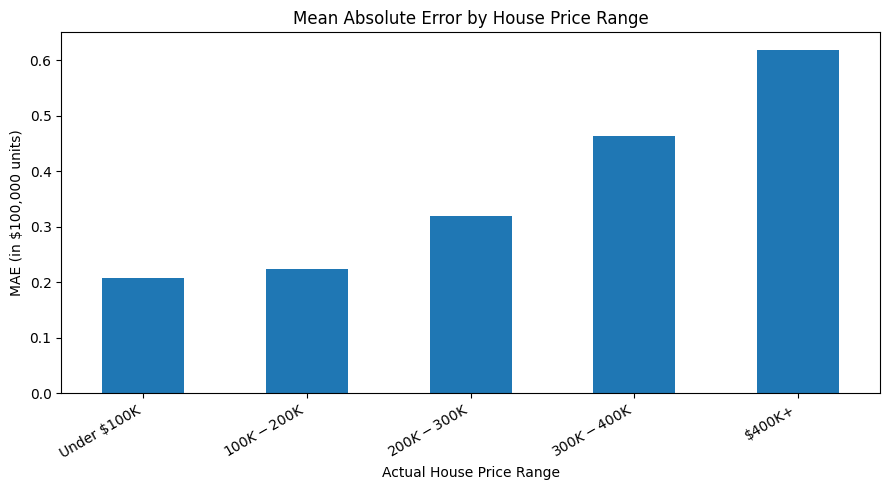

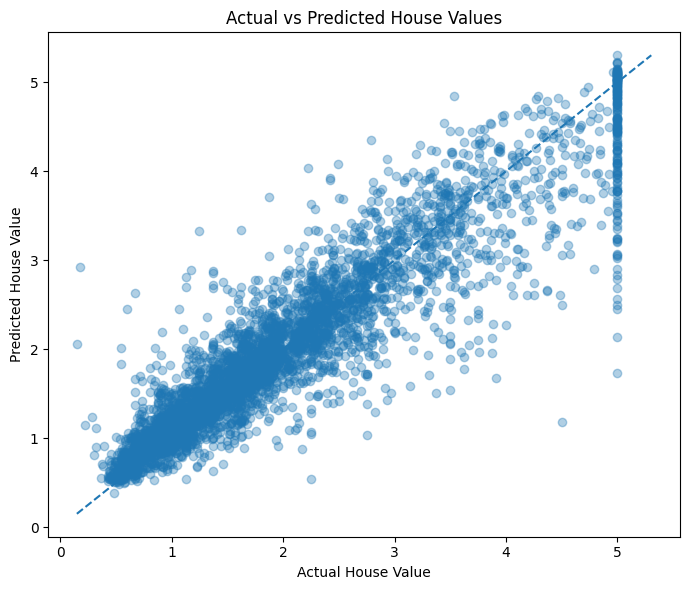

In [9]:

# Plot 1: Prediction error by actual price range
plt.figure(figsize=(9, 5))
price_error_analysis["MAE"].plot(kind="bar")
plt.title("Mean Absolute Error by House Price Range")
plt.xlabel("Actual House Price Range")
plt.ylabel("MAE (in $100,000 units)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Plot 2: Actual vs predicted values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, tuned_pred, alpha=0.35)

# Ideal prediction line
min_value = min(y_test.min(), tuned_pred.min())
max_value = max(y_test.max(), tuned_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.tight_layout()
plt.show()


### Error Analysis and Failure Patterns

The tuned HistGradientBoostingRegressor achieved a test MAE of 0.2999, RMSE of 0.4518, and R² of 0.8442. Its RMSE was approximately 39.40% lower than the Linear Regression baseline.

**Errors by house price range**

- **Under $100K:** MAE was 0.208, indicating comparatively lower prediction errors.
- **$100K–$200K:** MAE was 0.224, showing similar performance to the lowest price group.
- **$200K–$300K:** MAE increased to 0.320.
- **$300K–$400K:** MAE increased further to 0.463.
- **$400K+:** MAE reached 0.619, the highest among the groups. The average signed error was +0.552, indicating that the model underpredicted prices in this group on average.

**Why does the model fail?**

The results suggest that the model is less accurate for expensive houses. Possible reasons include more complex relationships between location and price, factors not represented in the available features, and fewer examples of high-value houses. The dataset also caps its target values at approximately $500,000, limiting what the model can learn about properties above that level.

These findings describe patterns in this test set; they do not prove that price alone causes the errors.

### Recommendation and Verdict

The tuned model substantially outperformed the Linear Regression baseline on the held-out test set. It is a promising educational model for exploring house-value prediction, but it should not be used as the sole basis for real property valuations.

Before real-world use, it would require evaluation on newer data, validation in different locations and price ranges, and additional features such as property condition and more detailed local market information. The target-value cap is a particularly important limitation.

**Verdict:** Suitable for an educational prototype and further testing, but not yet reliable enough for independent real-world valuation decisions.